# End-to-End Customer Churn Prediction & Explainable Retention Analytics Pipeline
**Organization:** The Skybrisk (Data Science Internship — Batch: Feb 20, 2026 to May 20, 2026)  
**Intern:** Mohd Abidullah Shareef (`EMP20250320-02677`)  
**Academic Submission:** Muffakham Jah College of Engineering & Technology (MJCET), CSE (AI & ML) VII Semester  
**Dataset:** [IBM / Kaggle Telco Customer Churn Dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) ($N = 7,043$ subscribers, $21$ attributes)


In [1]:
from churn_pipeline import TelcoChurnPipeline, run_full_pipeline
import pandas as pd

pipeline = TelcoChurnPipeline(random_state=42)
df = pipeline.load_and_clean_data('WA_Fn-UseC_-Telco-Customer-Churn.csv')
print(f'Loaded {df.shape[0]} rows, fixed {pipeline.eda_summary["n_whitespace_total_charges_fixed"]} blank TotalCharges entries.')
print('Churn counts:', pipeline.eda_summary['churn_counts'])


[1/5] Loading and cleaning Telco Customer Churn dataset...
      Loaded 7043 rows, fixed 11 blank TotalCharges entries. Overall churn rate: 26.54%
      Retained (0): 5174 | Churned (1): 1869


In [2]:
# Statistical Hypothesis Testing: Mann-Whitney U (Continuous) & Chi-Square / Cramer's V (Categorical)
stats_df = pipeline.run_statistical_tests(df)
print('Statistical Hypothesis Testing (Top Features by Effect Size):')
print(stats_df.to_string(index=False))


Statistical Hypothesis Testing (Top Features by Effect Size):
         Feature        Type           Test    Statistic       p_value  Effect_Size  Retained_Mean  Churned_Mean  Significant_at_0.001
          tenure  Continuous Mann-Whitney U 7.935180e+06  0.000000e+00     0.641160      36.923270     12.037988                  True
        Contract Categorical     Chi-Square 1.843807e+03  0.000000e+00     0.511657            NaN           NaN                  True
  MonthlyCharges  Continuous Mann-Whitney U 2.646268e+06 1.426227e-185     0.452697      59.445872     80.976404                  True
    TotalCharges  Continuous Mann-Whitney U 6.939396e+06 1.157149e-171     0.435212    2335.033910    983.254917                  True
 InternetService Categorical     Chi-Square 1.078619e+03 6.037069e-235     0.391341            NaN           NaN                  True
  OnlineSecurity Categorical     Chi-Square 7.722153e+02 2.068150e-168     0.331124            NaN           NaN                

In [3]:
# Feature Engineering, 80/20 Stratified Split, 5-Fold Stratified CV & GridSearchCV Tuning
summary_df, bench_dict = pipeline.train_and_benchmark(df, test_size=0.20)
print(summary_df[['Model', 'CV_ROC_AUC_Mean', 'Test_Accuracy', 'Test_Precision', 'Test_Recall', 'Test_F1_Score', 'Test_ROC_AUC', 'Test_PR_AUC']].to_string(index=False))


--- MODEL BENCHMARKING SUMMARY (5-FOLD STRATIFIED CV + HOLD-OUT TEST SET n=1,409) ---
Model                                            | 5-Fold CV AUC | Test Acc | Precision | Recall | F1-Score | Test ROC-AUC | Test PR-AUC
-------------------------------------------------|---------------|----------|-----------|--------|----------|--------------|------------
Proposed Hybrid Soft-Voting Ensemble (GBM+RF+LR) | 0.9541        | 0.8957   | 0.7933    | 0.8209 | 0.8068   | 0.9520       | 0.8872    
Logistic Regression (Tuned L2)                   | 0.9554        | 0.8652   | 0.6847    | 0.9118 | 0.7821   | 0.9513       | 0.8840    
Gradient Boosting (Tuned GBM)                    | 0.9524        | 0.8886   | 0.7719    | 0.8235 | 0.7969   | 0.9497       | 0.8840    
Extra Trees (Randomized Ensemble)                | 0.9504        | 0.8453   | 0.6466    | 0.9198 | 0.7594   | 0.9473       | 0.8812    
Random Forest (Tuned Ensemble)                   | 0.9492        | 0.8439   | 0.6458    | 0.9118

--- RETENTION CAMPAIGN ROI SIMULATION ON HOLD-OUT COHORT ---
Test Cohort Size                    : 1409 subscribers
Total Actual Churners in Test Set   : 374 (26.54%)
Targeted Subscribers (Med/High Risk): 536
True Churners Captured in Target    : 347 (92.78% Recall)
Estimated Campaign Cost ($45/target): $24,120.00
Gross Annual Revenue Saved (40% eff): $137,036.17
Net Annual Financial Benefit        : $112,916.17 (ROI: 468.1%)


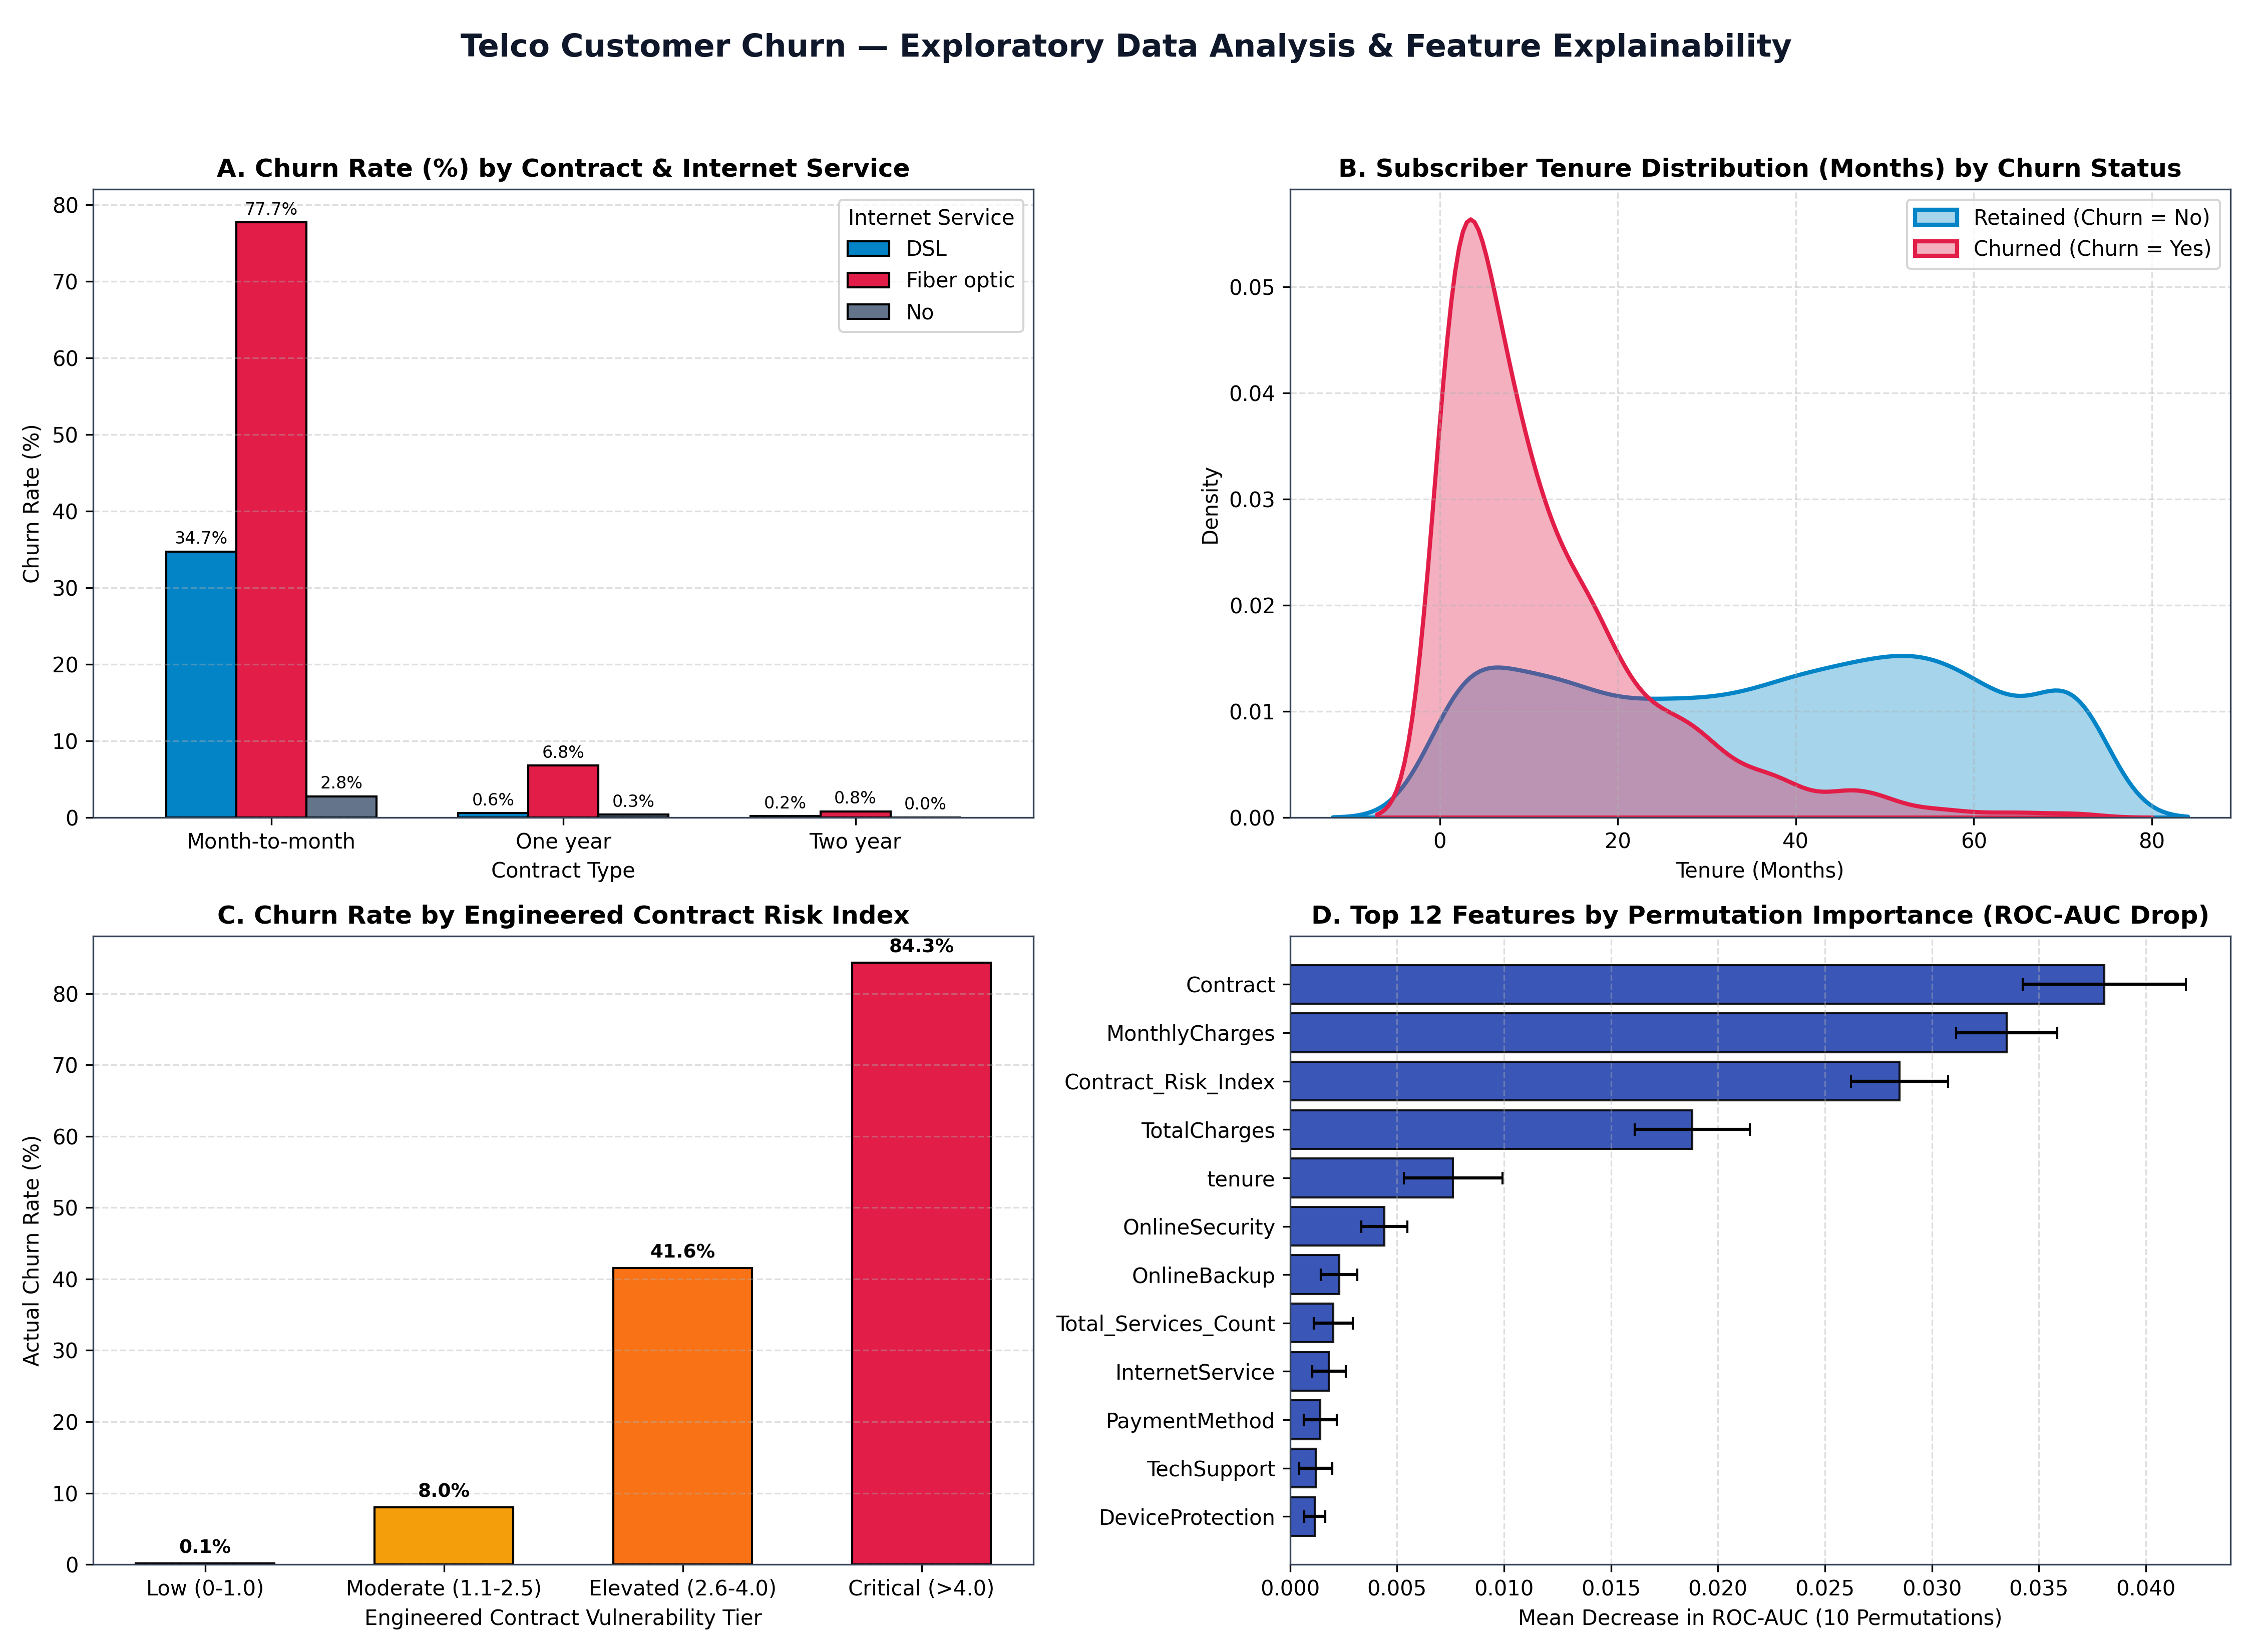

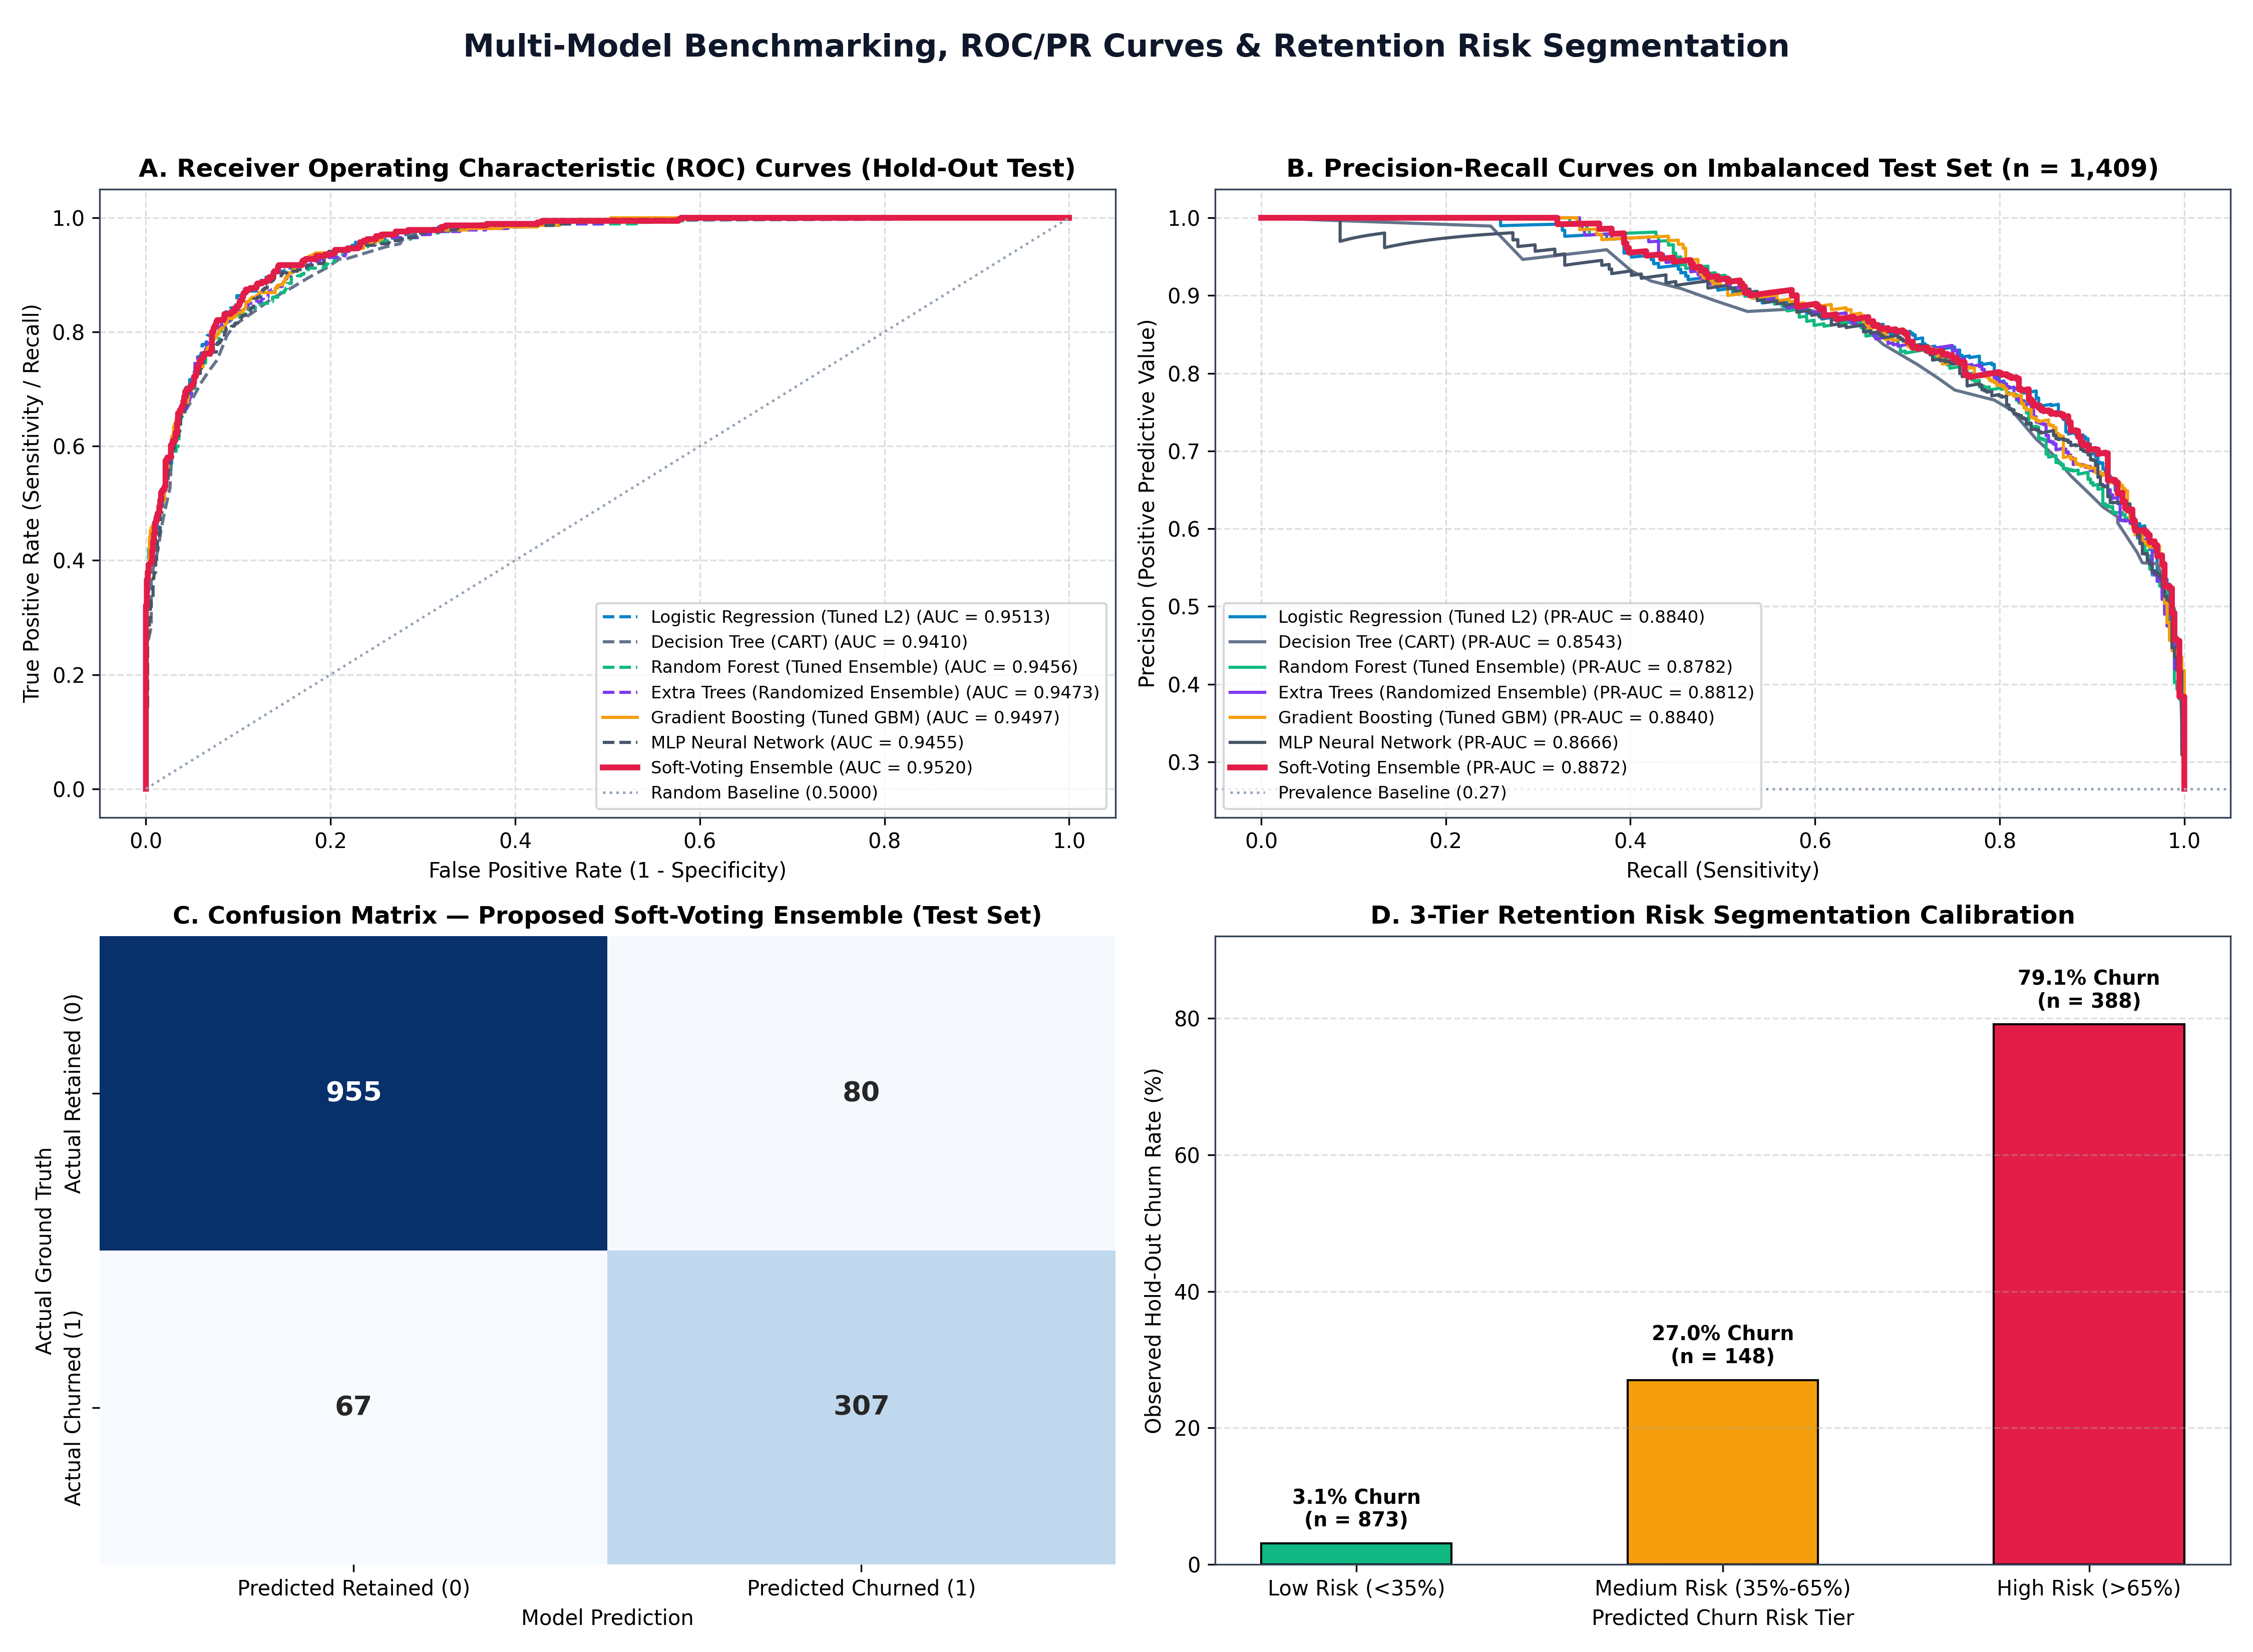

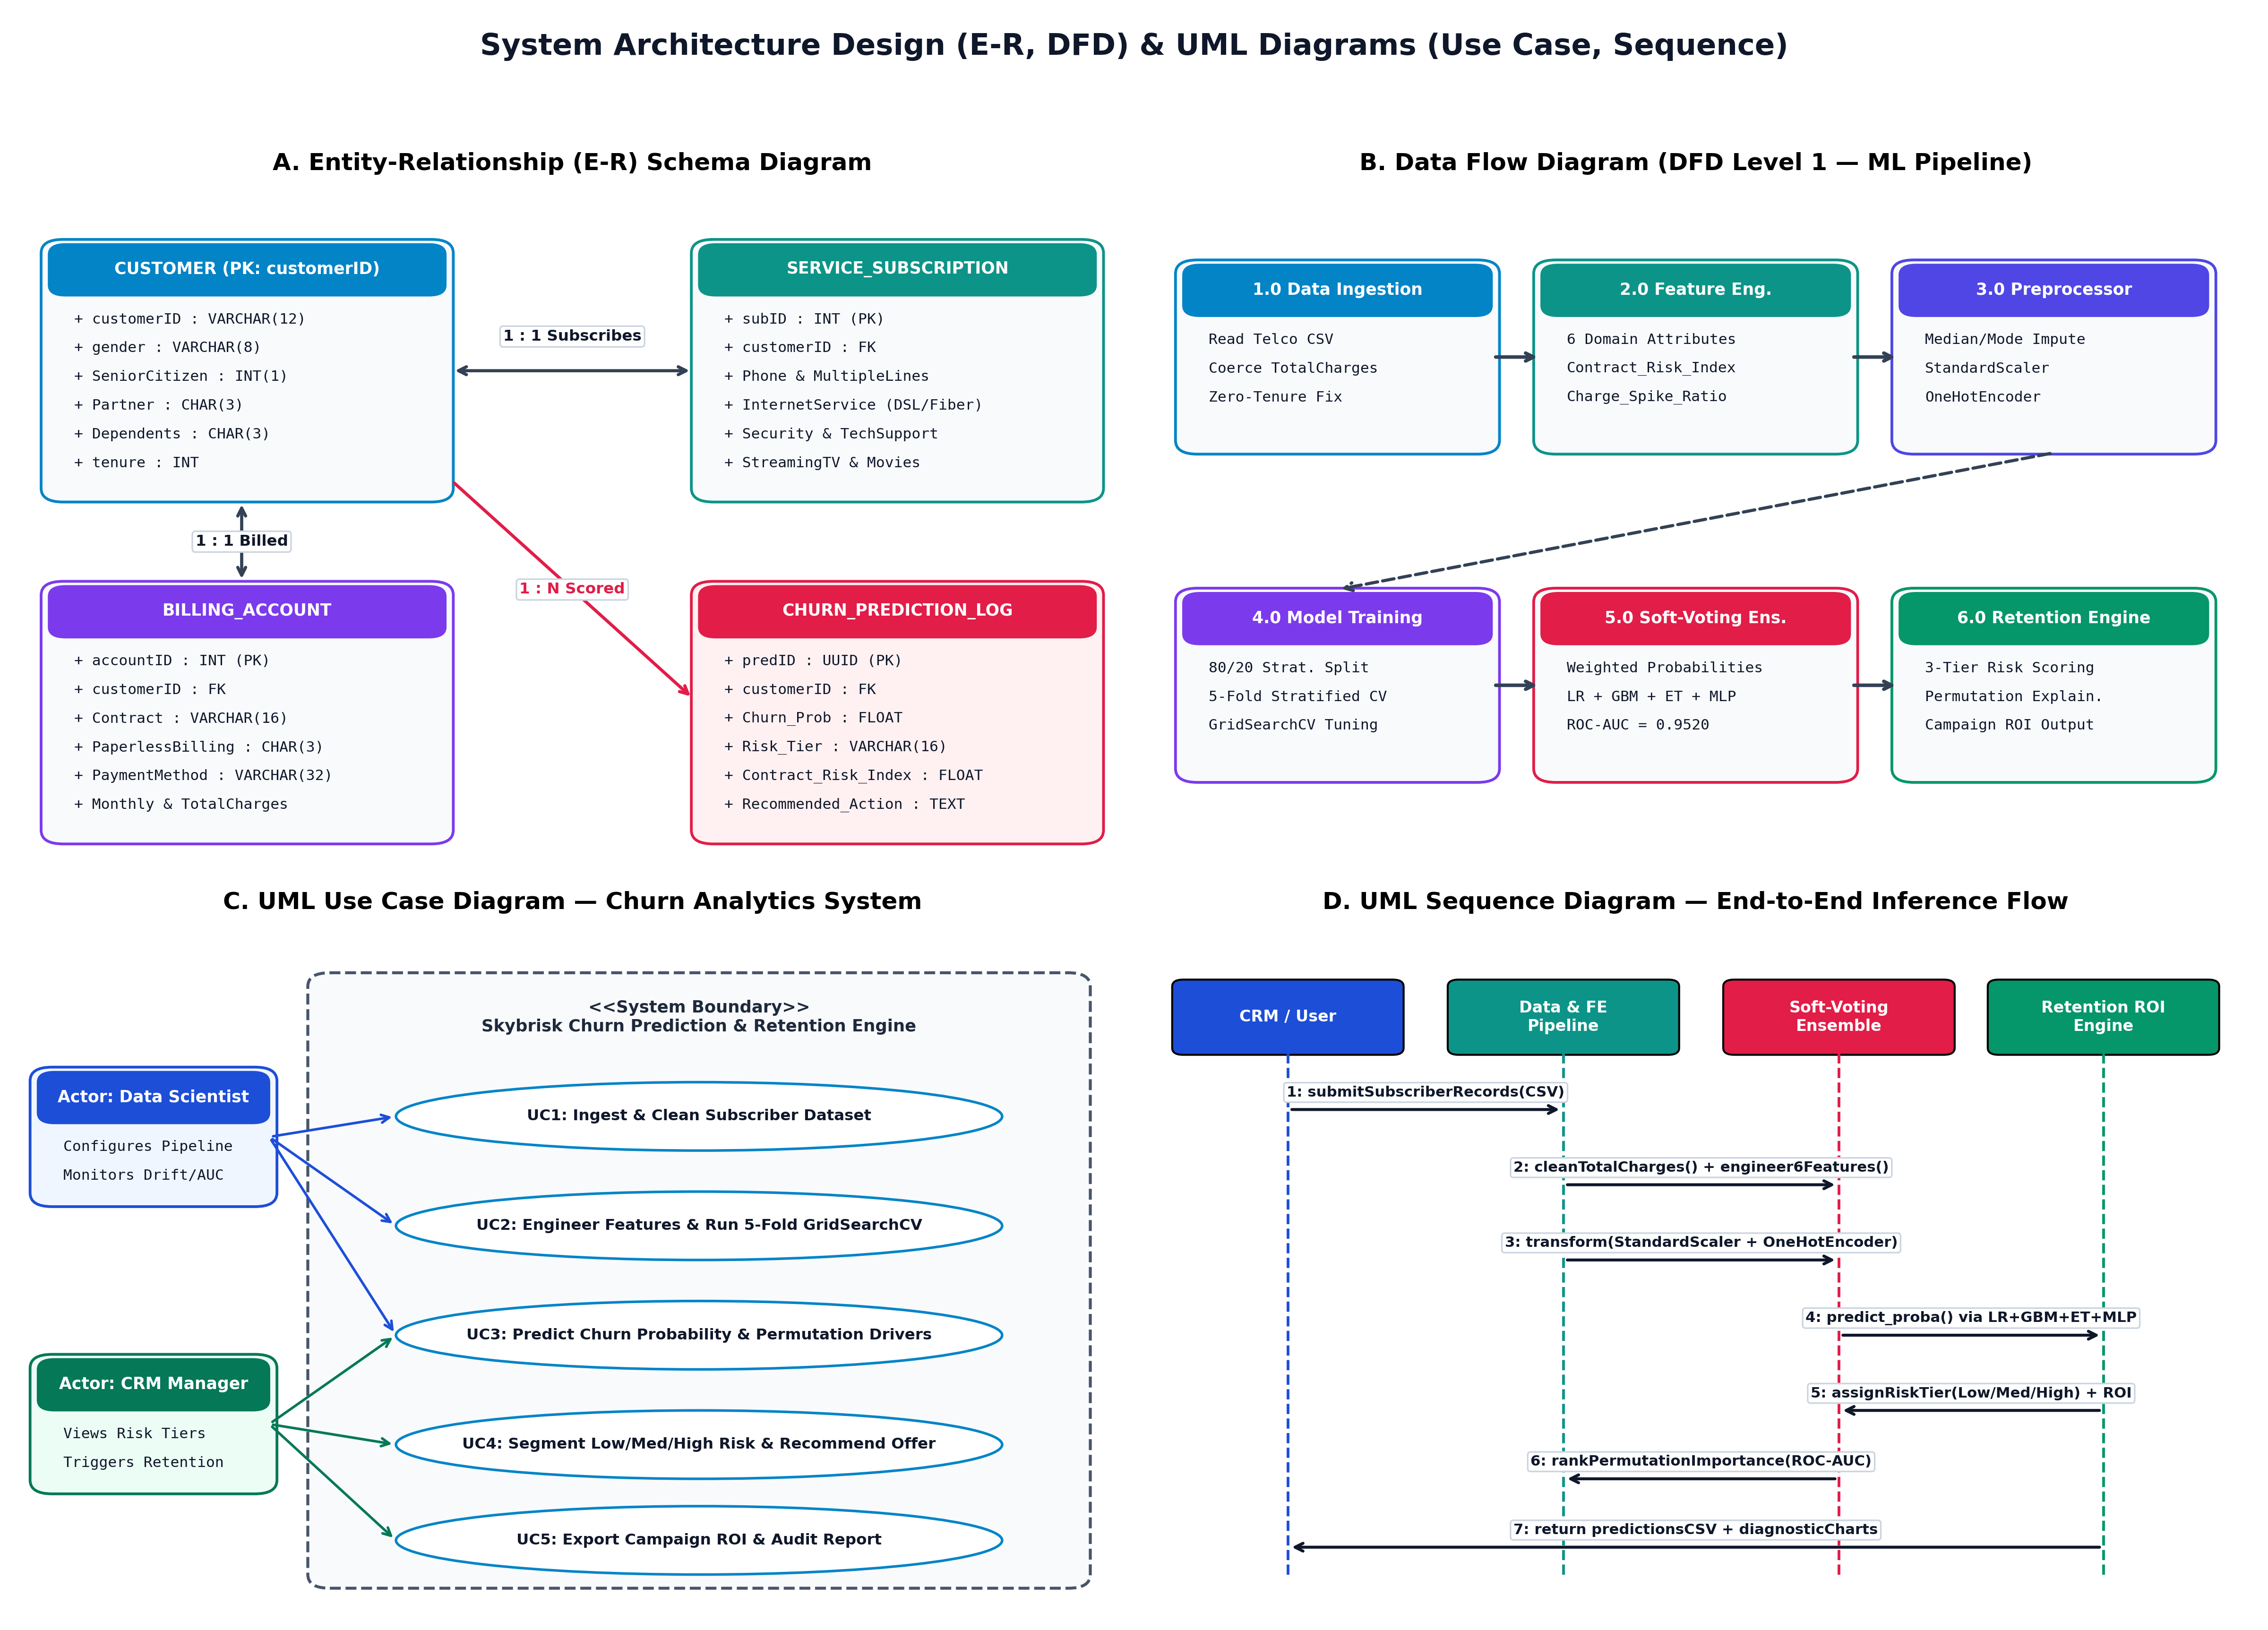

In [4]:
# Permutation Feature Importance, 3-Tier Risk Segmentation & Diagnostic Visualizations
imp_df = pipeline.compute_feature_importance()
pred_df, roi_summary = pipeline.generate_risk_segmentation_and_roi()
pipeline.save_diagnostic_charts(df, summary_df, imp_df, pred_df, '.')
